In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Paths

INPUT = Path("/scratch/project_2010417/paper3/toronto-bike-exposure/data/processed/routing_pilot_1000_routes.gpkg")
OUTDIR = Path("/scratch/project_2010417/paper3/toronto-bike-exposure/data/outputs/maps")
OUTDIR.mkdir(parents=True, exist_ok=True)

# Load routes
routes = gpd.read_file(INPUT)

# Project to a metric CRS for better plotting / lengths if needed
routes_utm = routes.to_crs("EPSG:26917")

print(routes_utm.head())
print("Trips:", len(routes_utm))
print(routes_utm.columns.tolist())

    Trip_Id  Trip_Duration Start_Station_Id          Start_Time  \
0  29342016            161             7524 2024-06-18 18:09:32   
1  29367543            394             7065 2024-06-19 15:13:48   
2  29337284           3102             7203 2024-06-18 16:50:17   
3  29246401           6044             7354 2024-06-15 15:28:39   
4  29260101           1020             7152 2024-06-15 21:20:19   

                              Start_Station_Name End_Station_Id  \
0                                    Lisgar Park           7035   
1                    Dundas St E / Parliament St           7041   
2  Bathurst St/Queens Quay(Billy Bishop Airport)           7016   
3       Tommy Thompson Park (Leslie Street Spit)           7731   
4                     Ossington Ave / Bloor St W           7234   

             End_Time                         End_Station_Name  Bike_Id  \
0 2024-06-18 18:12:13               Queen St W / Ossington Ave     6165   
1 2024-06-19 15:20:22                     Ed

In [6]:
routes_utm[[
    "Start_Station_Id",
    "End_Station_Id",
    "route_distance_m",
    "route_time_min",
    "actual_time_min",
    "duration_difference_min"
]].describe()

,route_distance_m,route_time_min,actual_time_min,duration_difference_min
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,2658.255972,9.423131,14.775300,5.352169
std,1857.212372,6.149970,11.731512,9.068078
min,195.636000,0.851800,1.250000,-8.620717
25%,1343.408250,5.171979,7.287500,0.941175
50%,2188.682500,7.921658,11.708333,2.852608
75%,3475.746250,12.090800,18.233333,5.996687
max,14521.315000,48.148767,100.733333,80.234133


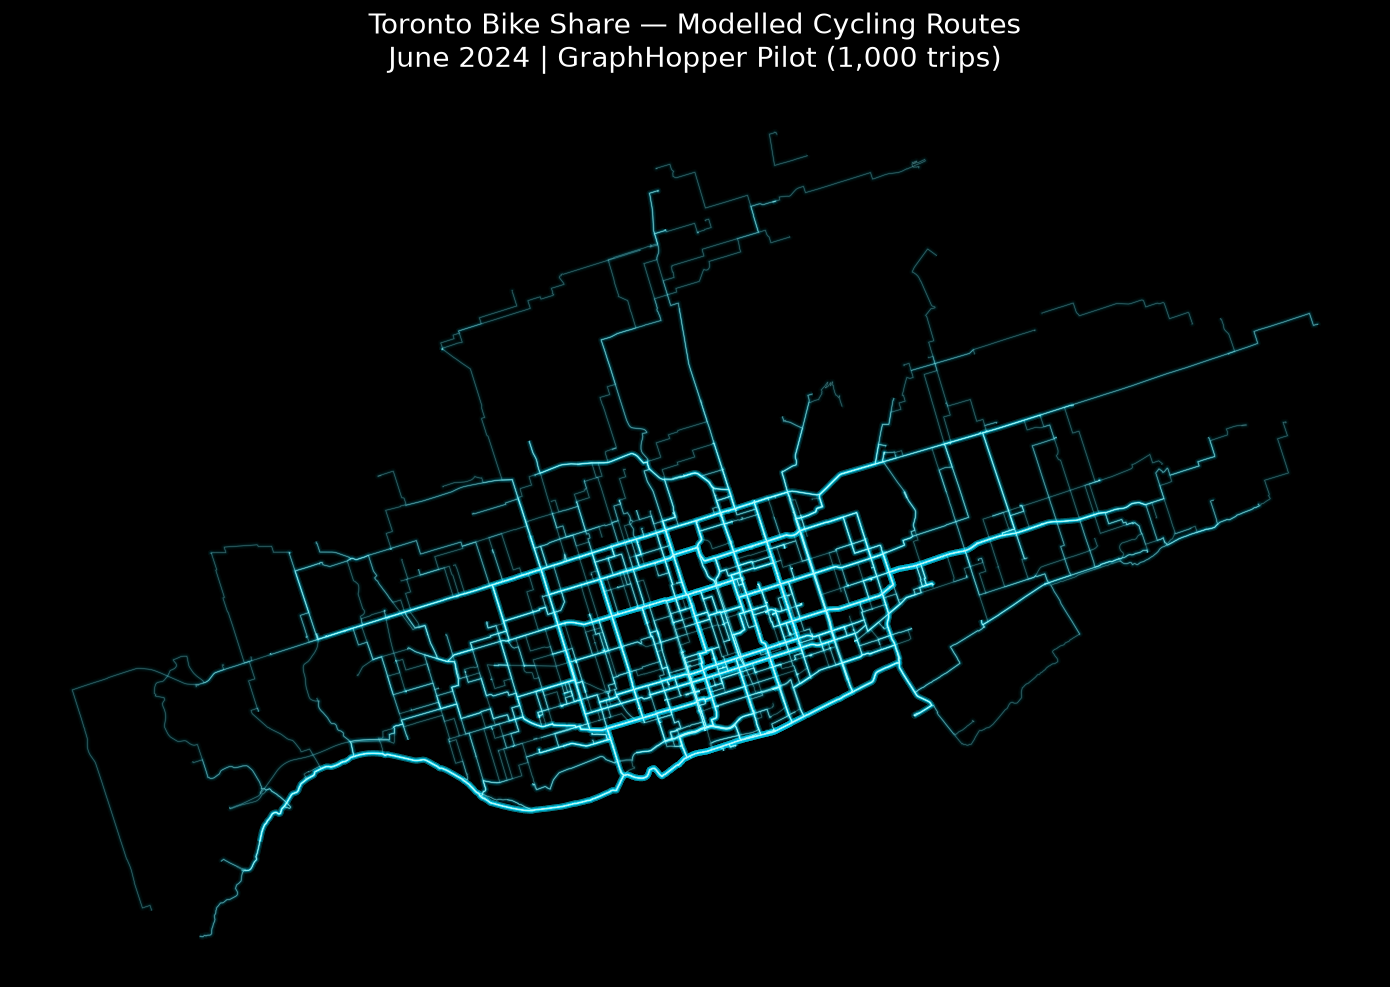

Saved: /scratch/project_2010417/paper3/toronto-bike-exposure/data/outputs/maps/toronto_routes_glow_dark.png


In [7]:
fig, ax = plt.subplots(figsize=(14, 12), facecolor="black")
ax.set_facecolor("black")

# Glow layers: thick + faint first, then sharper line on top
routes_utm.plot(
    ax=ax,
    linewidth=4.5,
    color="#00e5ff",
    alpha=0.03
)

routes_utm.plot(
    ax=ax,
    linewidth=2.5,
    color="#00d4ff",
    alpha=0.06
)

routes_utm.plot(
    ax=ax,
    linewidth=1.2,
    color="#43f0ff",
    alpha=0.12
)

routes_utm.plot(
    ax=ax,
    linewidth=0.35,
    color="#b8ffff",
    alpha=0.35
)

ax.set_title(
    "Toronto Bike Share — Modelled Cycling Routes\nJune 2024 | GraphHopper Pilot (1,000 trips)",
    color="white",
    fontsize=20,
    pad=18
)

ax.set_axis_off()
plt.tight_layout()

outfile = OUTDIR / "toronto_routes_glow_dark.png"
plt.savefig(outfile, dpi=300, facecolor="black", bbox_inches="tight")
plt.show()

print("Saved:", outfile)

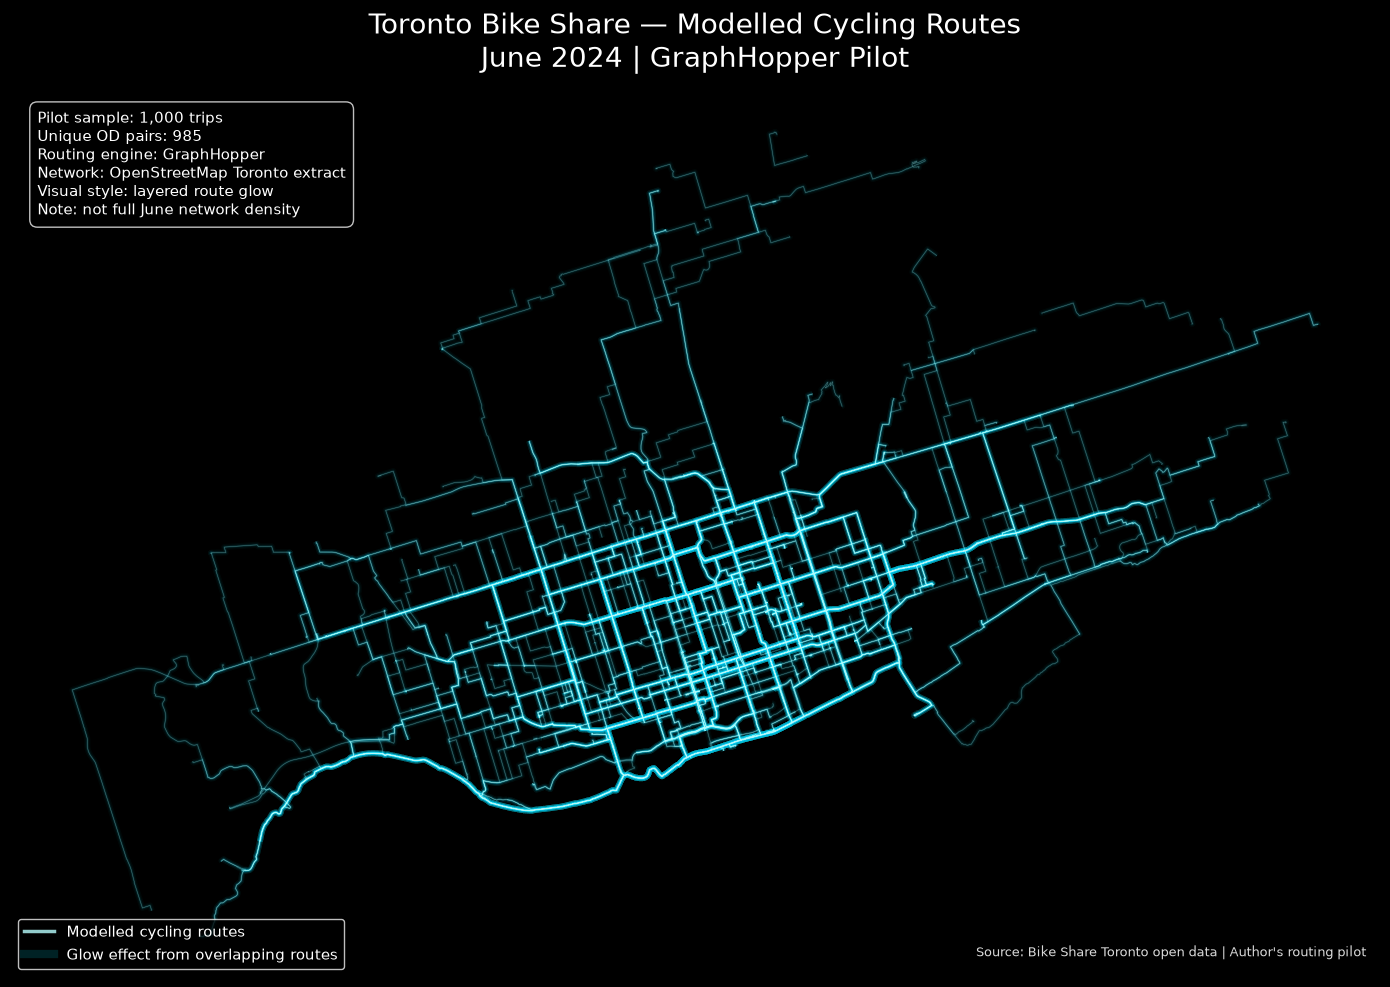

Saved: /scratch/project_2010417/paper3/toronto-bike-exposure/data/outputs/maps/toronto_routes_glow_dark_annotated.png


In [14]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(14, 12), facecolor="black")
ax.set_facecolor("black")

# Glow layers
routes_utm.plot(
    ax=ax,
    linewidth=4.5,
    color="#00e5ff",
    alpha=0.03
)

routes_utm.plot(
    ax=ax,
    linewidth=2.5,
    color="#00d4ff",
    alpha=0.06
)

routes_utm.plot(
    ax=ax,
    linewidth=1.2,
    color="#43f0ff",
    alpha=0.12
)

routes_utm.plot(
    ax=ax,
    linewidth=0.35,
    color="#b8ffff",
    alpha=0.35
)

# Title
ax.set_title(
    "Toronto Bike Share — Modelled Cycling Routes\n"
    "June 2024 | GraphHopper Pilot",
    color="white",
    fontsize=20,
    pad=18
)

# ---- Custom legend ----
legend_elements = [
    Line2D(
        [0], [0],
        color="#b8ffff",
        lw=2.5,
        alpha=0.8,
        label="Modelled cycling routes"
    ),
    Line2D(
        [0], [0],
        color="#00e5ff",
        lw=6,
        alpha=0.15,
        label="Glow effect from overlapping routes"
    )
]

leg = ax.legend(
    handles=legend_elements,
    loc="lower left",
    frameon=True,
    facecolor="black",
    edgecolor="white",
    framealpha=0.75,
    fontsize=11
)

for text in leg.get_texts():
    text.set_color("white")

# ---- Info box ----
info_text = (
    f"Pilot sample: {len(routes_utm):,} trips\n"
    f"Unique OD pairs: {routes_utm[['Start_Station_Id','End_Station_Id']].drop_duplicates().shape[0]:,}\n"
    f"Routing engine: GraphHopper\n"
    f"Network: OpenStreetMap Toronto extract\n"
    f"Visual style: layered route glow\n"
    f"Note: not full June network density"
)

ax.text(
    0.02, 0.98,
    info_text,
    transform=ax.transAxes,
    fontsize=11,
    color="white",
    va="top",
    ha="left",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="black",
        edgecolor="white",
        alpha=0.75
    )
)

# Optional small source note
ax.text(
    0.99, 0.02,
    "Source: Bike Share Toronto open data | Author's routing pilot",
    transform=ax.transAxes,
    fontsize=9,
    color="white",
    va="bottom",
    ha="right",
    alpha=0.85
)

ax.set_axis_off()
plt.tight_layout()

outfile = OUTDIR / "toronto_routes_glow_dark_annotated.png"
plt.savefig(outfile, dpi=300, facecolor="black", bbox_inches="tight")
plt.show()

print("Saved:", outfile)

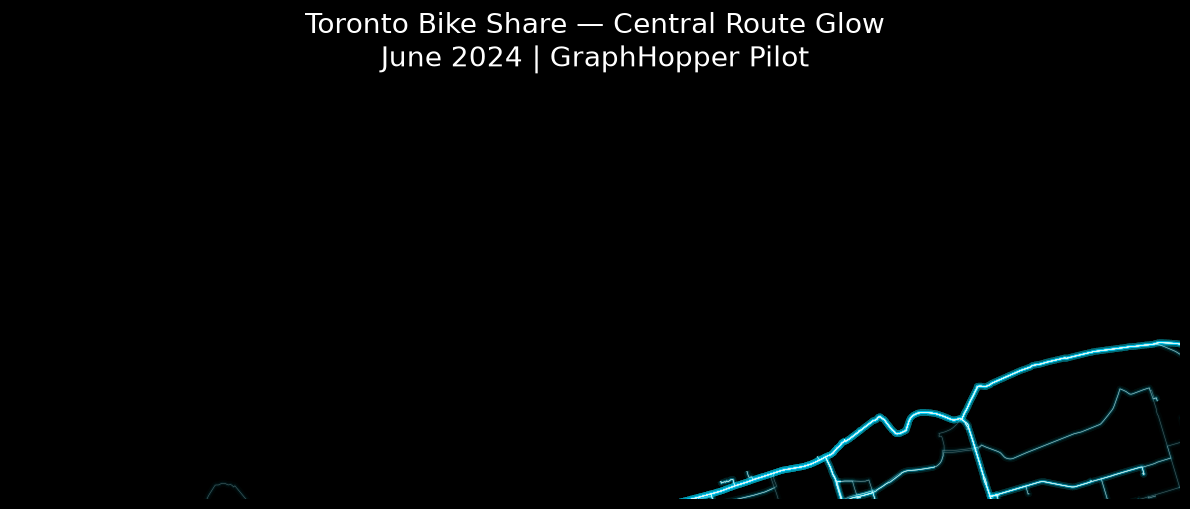

Saved: /scratch/project_2010417/paper3/toronto-bike-exposure/data/outputs/maps/toronto_routes_glow_central_dark.png


In [8]:
fig, ax = plt.subplots(figsize=(12, 12), facecolor="black")
ax.set_facecolor("black")

routes_utm.plot(ax=ax, linewidth=5.0, color="#00e5ff", alpha=0.025)
routes_utm.plot(ax=ax, linewidth=2.2, color="#00d4ff", alpha=0.08)
routes_utm.plot(ax=ax, linewidth=0.45, color="#d7ffff", alpha=0.30)

# Optional manual zoom — adjust after seeing the first full map
xmin, ymin, xmax, ymax = routes_utm.total_bounds
ax.set_xlim(xmin + 15000, xmax - 12000)
ax.set_ylim(ymin + 3000, ymax - 12000)

ax.set_title(
    "Toronto Bike Share — Central Route Glow\nJune 2024 | GraphHopper Pilot",
    color="white",
    fontsize=20,
    pad=18
)

ax.set_axis_off()
plt.tight_layout()

outfile = OUTDIR / "toronto_routes_glow_central_dark.png"
plt.savefig(outfile, dpi=300, facecolor="black", bbox_inches="tight")
plt.show()

print("Saved:", outfile)

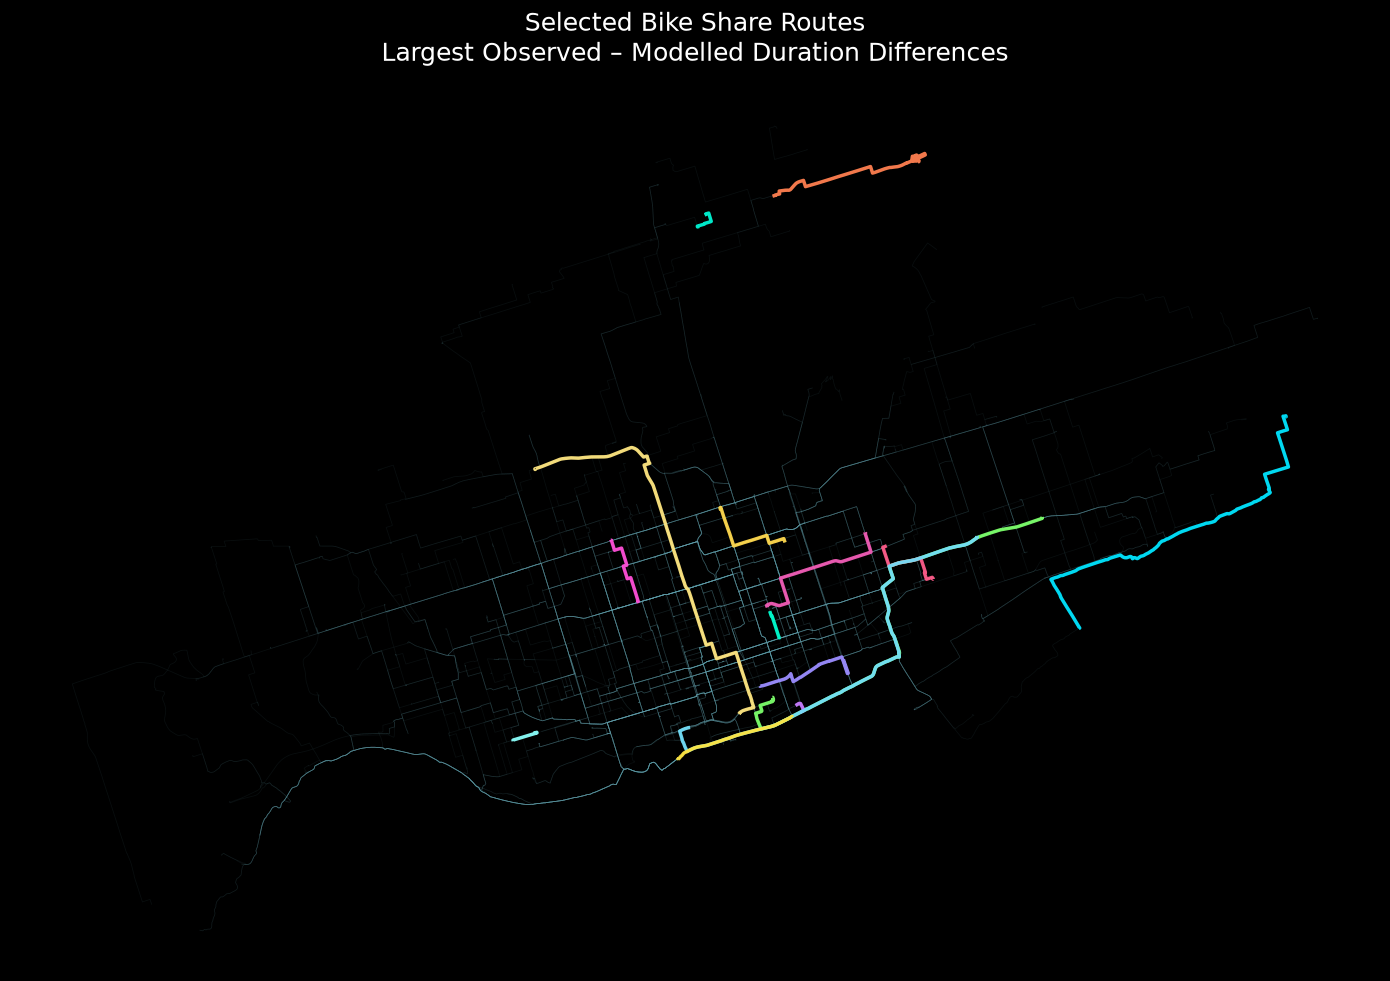

Saved: /scratch/project_2010417/paper3/toronto-bike-exposure/data/outputs/maps/toronto_selected_routes_highlighted.png


In [9]:
# Remove weird / missing values if necessary
sel = routes_utm.copy()
sel = sel.replace([np.inf, -np.inf], np.nan)
sel = sel.dropna(subset=["duration_difference_min"])

# Pick 15 routes with largest positive difference
selected = sel.sort_values("duration_difference_min", ascending=False).head(15).copy()

fig, ax = plt.subplots(figsize=(14, 12), facecolor="black")
ax.set_facecolor("black")

# Background: all routes in faint gray-blue
routes_utm.plot(
    ax=ax,
    linewidth=0.6,
    color="#6aa7b3",
    alpha=0.08
)

# Neon-like highlight colors
colors = [
    "#00e5ff", "#ff4fd8", "#7cff6b", "#ffd84d", "#9b8cff",
    "#ff7f50", "#00ffd0", "#ff5c8a", "#8bfffb", "#ffe680",
    "#c77dff", "#72ddf7", "#f15bb5", "#fee440", "#00f5d4"
]

for i, (_, row) in enumerate(selected.iterrows()):
    gpd.GeoSeries([row.geometry], crs=routes_utm.crs).plot(
        ax=ax,
        linewidth=2.5,
        color=colors[i % len(colors)],
        alpha=0.95
    )

ax.set_title(
    "Selected Bike Share Routes\nLargest Observed – Modelled Duration Differences",
    color="white",
    fontsize=18,
    pad=18
)

ax.set_axis_off()
plt.tight_layout()

outfile = OUTDIR / "toronto_selected_routes_highlighted.png"
plt.savefig(outfile, dpi=300, facecolor="black", bbox_inches="tight")
plt.show()

print("Saved:", outfile)

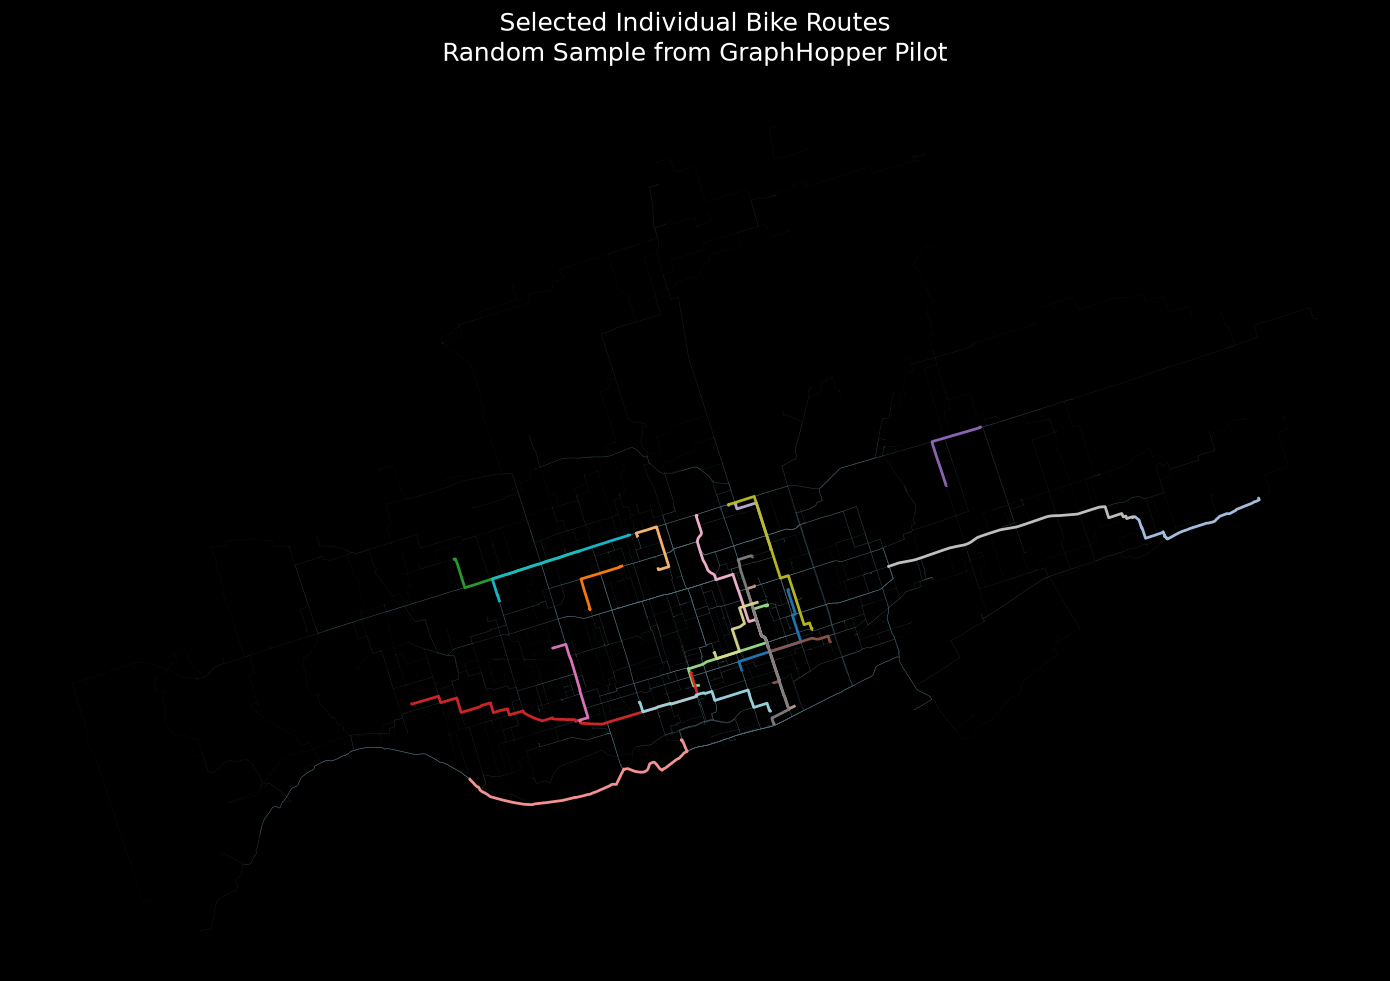

Saved: /scratch/project_2010417/paper3/toronto-bike-exposure/data/outputs/maps/toronto_selected_routes_random.png


In [10]:
np.random.seed(42)
selected_random = routes_utm.sample(20).copy()

fig, ax = plt.subplots(figsize=(14, 12), facecolor="black")
ax.set_facecolor("black")

routes_utm.plot(
    ax=ax,
    linewidth=0.5,
    color="#5f7d86",
    alpha=0.07
)

colors = plt.cm.tab20(np.linspace(0, 1, len(selected_random)))

for color, (_, row) in zip(colors, selected_random.iterrows()):
    gpd.GeoSeries([row.geometry], crs=routes_utm.crs).plot(
        ax=ax,
        linewidth=2.0,
        color=color,
        alpha=0.95
    )

ax.set_title(
    "Selected Individual Bike Routes\nRandom Sample from GraphHopper Pilot",
    color="white",
    fontsize=18,
    pad=18
)

ax.set_axis_off()
plt.tight_layout()

outfile = OUTDIR / "toronto_selected_routes_random.png"
plt.savefig(outfile, dpi=300, facecolor="black", bbox_inches="tight")
plt.show()

print("Saved:", outfile)

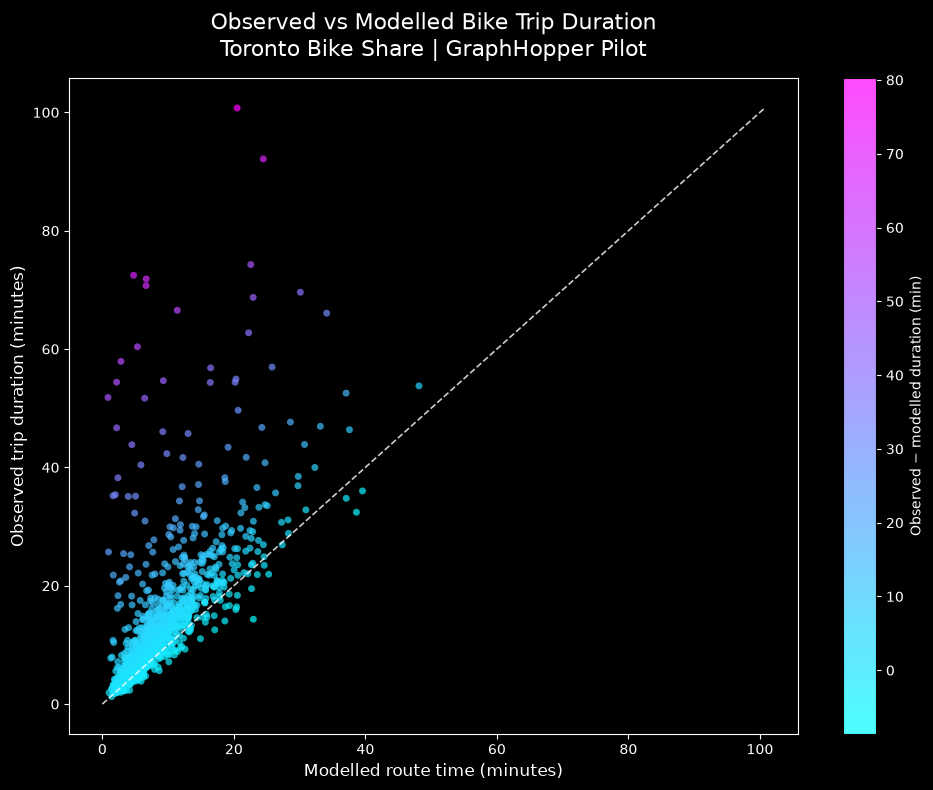

Saved: /scratch/project_2010417/paper3/toronto-bike-exposure/data/outputs/maps/toronto_duration_scatter_dark.png


In [11]:
df = routes_utm.copy()
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["actual_time_min", "route_time_min", "duration_difference_min"])

fig, ax = plt.subplots(figsize=(10, 8), facecolor="black")
ax.set_facecolor("black")

sc = ax.scatter(
    df["route_time_min"],
    df["actual_time_min"],
    c=df["duration_difference_min"],
    cmap="cool",
    alpha=0.7,
    s=25,
    edgecolors="none"
)

# 1:1 reference line
maxv = max(df["route_time_min"].max(), df["actual_time_min"].max())
ax.plot([0, maxv], [0, maxv], color="white", linestyle="--", linewidth=1.2, alpha=0.8)

ax.set_xlabel("Modelled route time (minutes)", color="white", fontsize=12)
ax.set_ylabel("Observed trip duration (minutes)", color="white", fontsize=12)
ax.set_title(
    "Observed vs Modelled Bike Trip Duration\nToronto Bike Share | GraphHopper Pilot",
    color="white",
    fontsize=16,
    pad=16
)

ax.tick_params(colors="white")
for spine in ax.spines.values():
    spine.set_color("white")

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Observed − modelled duration (min)", color="white")
cbar.ax.yaxis.set_tick_params(color="white")
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='white')

plt.tight_layout()

outfile = OUTDIR / "toronto_duration_scatter_dark.png"
plt.savefig(outfile, dpi=300, facecolor="black", bbox_inches="tight")
plt.show()

print("Saved:", outfile)

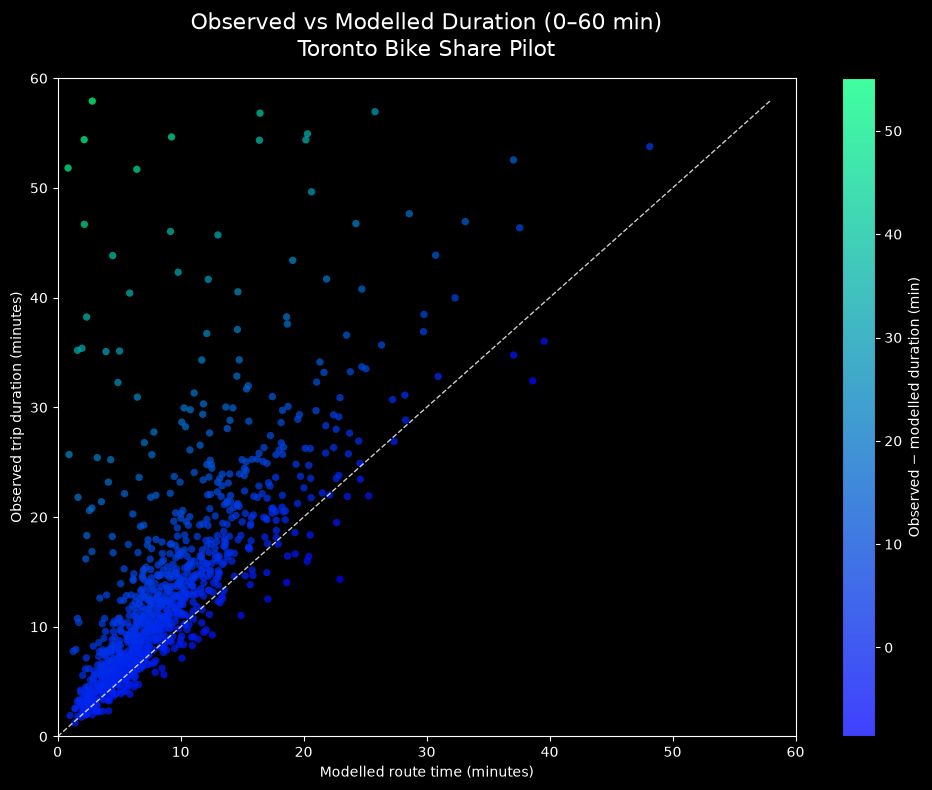

Saved: /scratch/project_2010417/paper3/toronto-bike-exposure/data/outputs/maps/toronto_duration_scatter_dark_zoom.png


In [12]:
df2 = df[
    (df["actual_time_min"] <= 60) &
    (df["route_time_min"] <= 60)
].copy()

fig, ax = plt.subplots(figsize=(10, 8), facecolor="black")
ax.set_facecolor("black")

sc = ax.scatter(
    df2["route_time_min"],
    df2["actual_time_min"],
    c=df2["duration_difference_min"],
    cmap="winter",
    alpha=0.75,
    s=28,
    edgecolors="none"
)

maxv = max(df2["route_time_min"].max(), df2["actual_time_min"].max())
ax.plot([0, maxv], [0, maxv], color="#ffffff", linestyle="--", linewidth=1.0, alpha=0.8)

ax.set_xlim(0, 60)
ax.set_ylim(0, 60)

ax.set_xlabel("Modelled route time (minutes)", color="white")
ax.set_ylabel("Observed trip duration (minutes)", color="white")
ax.set_title(
    "Observed vs Modelled Duration (0–60 min)\nToronto Bike Share Pilot",
    color="white",
    fontsize=16,
    pad=16
)

ax.tick_params(colors="white")
for spine in ax.spines.values():
    spine.set_color("white")

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Observed − modelled duration (min)", color="white")
cbar.ax.yaxis.set_tick_params(color="white")
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='white')

plt.tight_layout()

outfile = OUTDIR / "toronto_duration_scatter_dark_zoom.png"
plt.savefig(outfile, dpi=300, facecolor="black", bbox_inches="tight")
plt.show()

print("Saved:", outfile)

SyntaxError: invalid syntax. Maybe you meant '==' or ':=' instead of '='? (3333409680.py, line 2)